# Are the neurons that carry a Qwen fine-tune the ones a system prompt already moves, and can their jobs be named? (E102 stages A and B)

*Stage A 2026-11-05, stage B 2026-11-06. **Provisional**: fast lane, no independent check. Plan
`reports/plans/2026-11-05_plan_e102-qwen-carrying.md`; full numbers and scoring in
`reports/analyses/2026-11-05_analysis_e102-qwen-carrying.md`.*

## The answer

Real fine-tunes share the neurons a system prompt moves more than a random change does, nearly whatever they teach, so
that reading cannot tell reuse from new. We then had agents write each carrying neuron's job and tie it to one of four
tasks. The check of that judge failed to show power: neurons chosen because they fire at biography answers were tied to
the biography task half the time, against about a third for random neurons. That gap is too small to count, so by the
filed rule nothing else in stage B is read.


## What we were trying to test

`GOALS.md` asks whether a fine-tune strengthens something the model already does or teaches it something new. VPD is
one way to read that; this experiment is a cheaper way that needs no decomposition, so that VPD's readings have a
baseline to beat. It works on Qwen3-1.7B's MLP neurons: 28 blocks of 6,144, so 172,032 in all.

**The fine-tunes.** Two kinds, each at two seeds, saved by earlier runs and only read here.

- *The template fine-tune.* It teaches the model to lay out maths answers in a fixed "Given / Steps / The answer is"
  form. The unchanged model already does this when a system turn asks for it, and never does without one. So this
  fine-tune is labelled **reuse** by construction.
- *The TOFU fine-tune.* It teaches made-up facts about fictional authors. Read at its last step it has memorised them,
  so it is labelled **new**. We also read it at an early step, where its weight change has the same size as the
  template fine-tune's and it has not yet learned the facts. That matched state is a size control.
- *A random change.* A Gaussian change to every weight matrix, scaled so it moves the model's predictions on maths text
  as much as the template fine-tune does. It is the floor every reading is compared with.

**The carrying set.** For each fine-tune we keep the unchanged model's weights and let only the neurons' firing change
to what the fine-tuned model produces. Each neuron gets a first-order score: how much its changed firing raises the
log-probability of the training answers. The 1,024 neurons with the largest scores are the fine-tune's carrying set,
0.6% of all neurons. The template states are read on 64 template rows, the TOFU states and their random change on 128
TOFU rows.

**Two readings of a carrying set.**

- *Prompt overlap.* We run the unchanged model on the template items twice, with and without the system turn, and take
  the 1,024 neurons whose firing at the answers changes most. That is the **prompt's contrast set**: the neurons the
  model already uses to produce the layout when asked. Prompt overlap is the share of a carrying set inside it: 0 means
  none, 1 means all, and a random set of the same layer profile reads about 0.004.
- *Engaged share.* For each neuron we take its firing at the answer positions, before training, as a quantile of its
  firing on 1M tokens of web text. The engaged share is the median of that over a set: 0.5 means the set fires at the
  answers like at a typical web position, 1 means at its strongest.

**What each reference rules out.** The random change rules out "any change of this size picks prompt neurons". The
TOFU matched state was filed only as a size control for the engaged share, and its prompt overlap was printed unscored.
It turned out to be the most informative reference: it rules out "any real fine-tune of this size picks prompt
neurons". The positive control asks whether the contrast set is a real, stable set at all, by building it separately
from even and odd items.


## What we expected, and why

- **The contrast set would reproduce across item halves, and the random change's carrying set would sit outside it.**
  If not, the prompt overlap means nothing and the job stops. Filed bar: each comparison clears its reference by 0.2.
- **The template fine-tune's carrying sets would overlap the contrast set more than the random change's.** If the
  fine-tune reuses prompted behaviour, the neurons that carry its gain should be the ones the prompt already moves. To
  count, both seeds must beat the random change and every random draw, and their mean must clear it by more than a band
  set from the seed spread and the draws' spread.
- **The template's carrying neurons would already be engaged at the answers.** Same rule on the engaged share.
- **The TOFU matched states would read with the random change on the engaged share.** At that step nothing is learned.
- **The full TOFU states: no lean.** Biography prose may engage the unchanged model too.
- **The TOFU states' prompt overlap: printed, not scored.** No system prompt elicits fictional facts, so there was no
  prediction to make. We now think this was the comparison that mattered.


In [1]:
import json
from pathlib import Path

from IPython.display import Image, display

from commute.jobs import load_experiment

PLOT = load_experiment("qwen_carrying", "plot")
PLOT.main()  # redraws the three figures from score.json and states/*.json
FIG = Path("../experiments/qwen_carrying/figures")
RES = Path("../experiments/qwen_carrying/results")
score = json.loads((RES / "score.json").read_text())
per = score["per_state"]
c = score["control_i"]
print(f"contrast set, even items against odd items: {c['halves']:.3f}; largest random draw {c['draw_max']:.3f}")
print(f"random change's carrying set inside the contrast set: {c['gauss_overlap']:.3f}")


contrast set, even items against odd items: 0.956; largest random draw 0.031
random change's carrying set inside the contrast set: 0.035


## What we observed

The apparatus checked out first. With no change, every score read exactly zero. The unchanged model's answer
log-probabilities and every fine-tune's gain matched the earlier comparator run to six or more digits. The contrast set
built from even items shares 0.956 of itself with the one built from odd items, where the largest of 100 random draws
shares 0.031. The random change's carrying set has 0.035 of itself inside it. So the contrast set is real and stable,
and the positive control passed by a wide margin.

### Do the fine-tunes' carrying sets overlap the neurons the system prompt moves, more than a random change's?


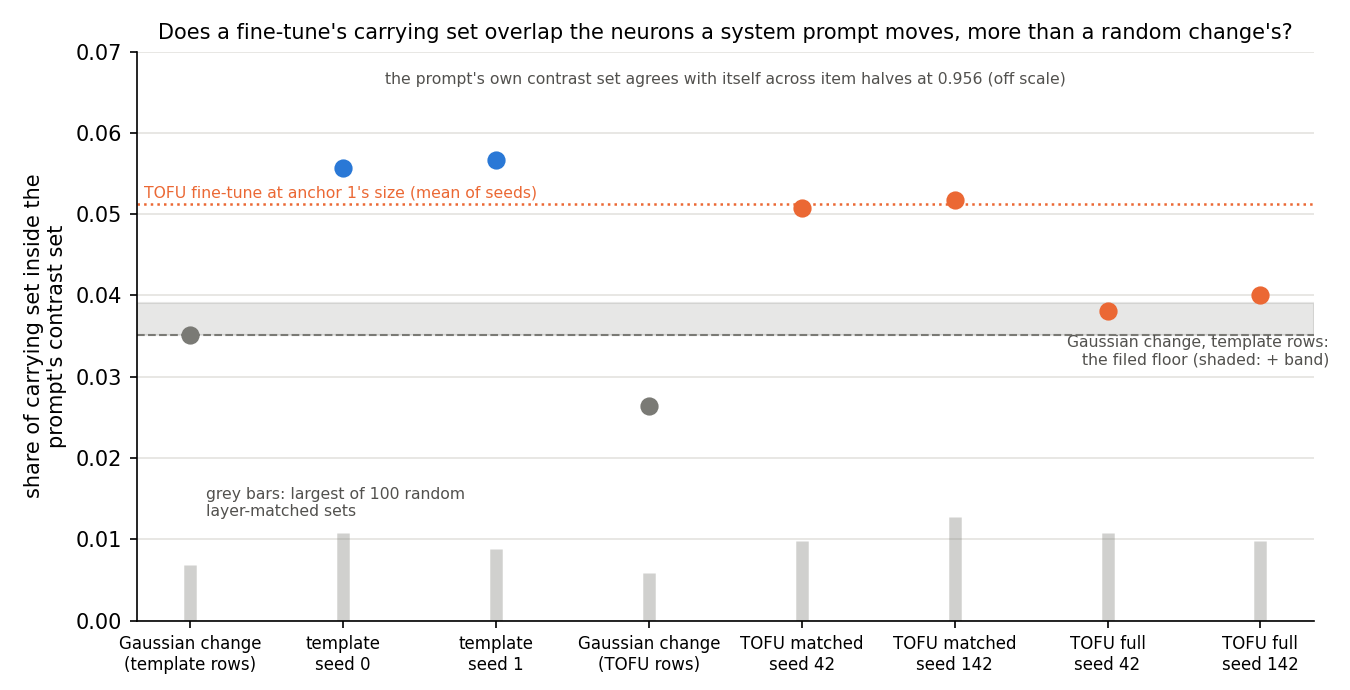

In [2]:
display(Image(FIG / "prompt_overlap.png", width=850))


**Reading it.** Yes, but not only the template fine-tune's. Both template seeds put about 5.6% of their carrying set
inside the prompt's contrast set, against 3.5% for the random change on the same rows. That clears the filed band of
0.4 points, so the filed prediction holds. The orange dotted line is the problem. The TOFU fine-tune at the same weight
size, which teaches unrelated facts, reads 5.1% at both seeds. Its own random change, read on the same TOFU rows, reads
only 2.6%.

So most of the template's lead over the random change is shared by a real fine-tune with the opposite label. Measured
against the TOFU matched states, the template's lead shrinks to about half a point, near the band. Real updates overlap
the prompt's neurons more than a random change does, nearly whatever they teach. The full TOFU states, 37 times larger,
fall back to 3.8 and 4.0%, just above the random change.

One reason the random change is a low floor: it matches the template's effect on maths text, but it barely moves the
template answers. Its gain on them is 0.04 nats a token, against the template fine-tune's 0.67, so its carrying set is
ranked on a far weaker signal. Every set, the random change's included, overlaps the contrast set about ten times more
than a random set of neurons does.


In [3]:
rows = [("template seed 0", "a1_s0"), ("template seed 1", "a1_s1"), ("random change, template rows", "gauss_a1"),
        ("TOFU matched seed 42", "a2_s42_matched"), ("TOFU matched seed 142", "a2_s142_matched"),
        ("TOFU full seed 42", "a2_s42_full"), ("TOFU full seed 142", "a2_s142_full"),
        ("random change, TOFU rows", "gauss_tofu")]
print(f"{'state':<30}{'prompt overlap':>15}{'largest draw':>14}")
for name, s in rows:
    print(f"{name:<30}{per[s]['prompt_overlap']:>15.3f}{max(per[s]['prompt_overlap_draws']):>14.3f}")


state                          prompt overlap  largest draw
template seed 0                         0.056         0.011
template seed 1                         0.057         0.009
random change, template rows            0.035         0.007
TOFU matched seed 42                    0.051         0.010
TOFU matched seed 142                   0.052         0.013
TOFU full seed 42                       0.038         0.011
TOFU full seed 142                      0.040         0.010
random change, TOFU rows                0.026         0.006


### Were the carrying neurons already firing at the answers before training?


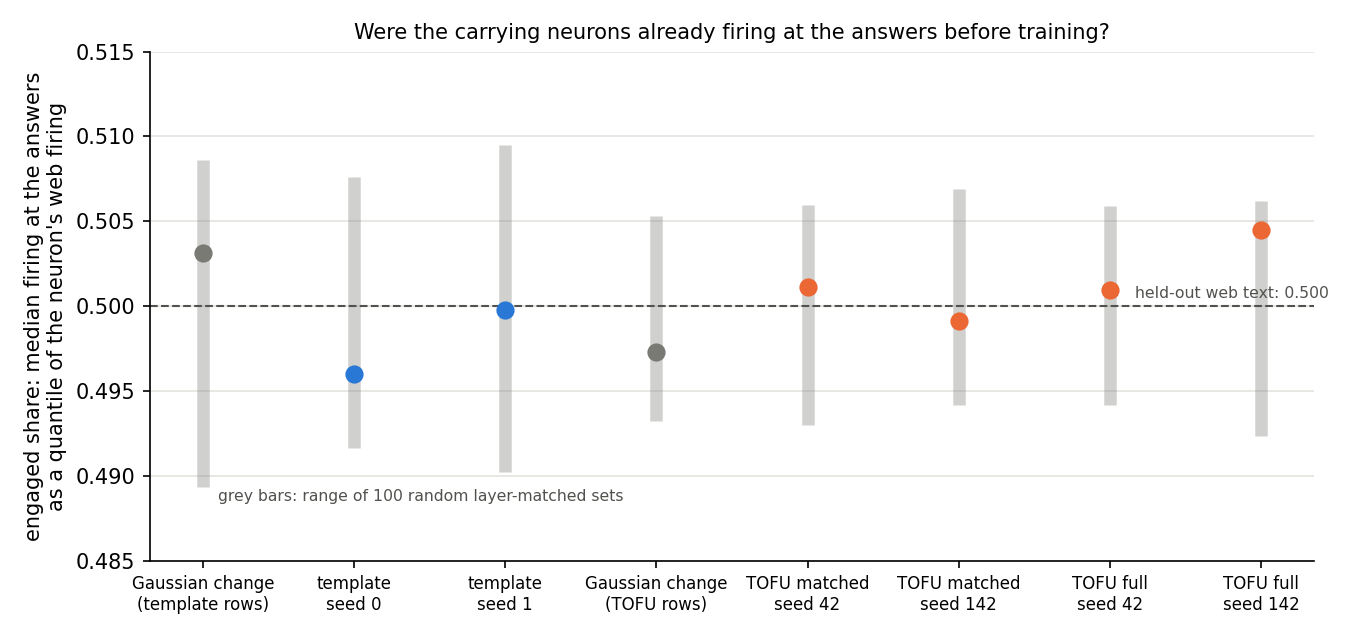

In [4]:
display(Image(FIG / "engaged.png", width=850))


**Reading it.** No set is more engaged than random neurons, so the template prediction failed. Every set, the random
change's included, has a median of 0.496 to 0.504. That is the value for typical web text, and each point sits inside
the range of its 100 random draws. The median over all 172,032 neurons on either row set is also 0.500. So the
carrying neurons fire at the answers no more than at an ordinary web position, for every update. The TOFU matched
states read with the random change, as filed, and so do the full TOFU states. The reading has no spread here, so it
cannot separate anything; it is not evidence against reuse.


### Is a carrying set specific to its fine-tune, or set by the rows it is read on?


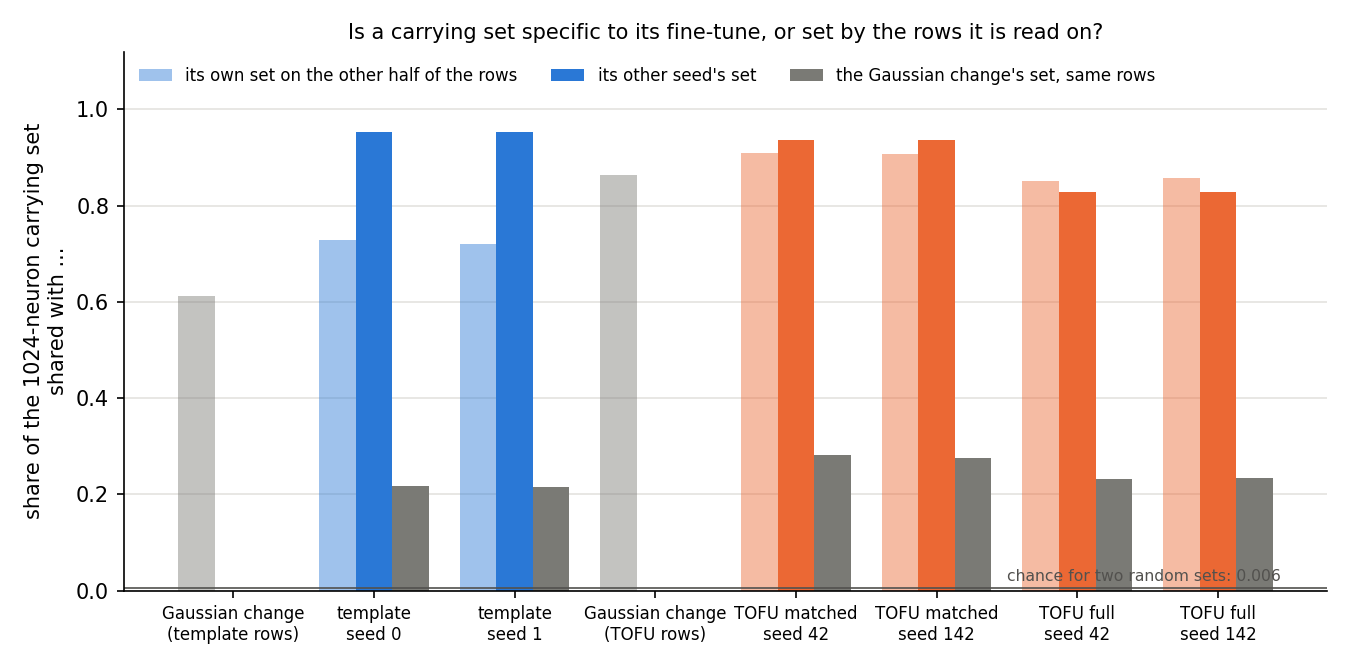

In [5]:
display(Image(FIG / "set_specificity.png", width=850))


**Reading it.** Specific to the fine-tune, but a set that reproduces across rows does not show that. The two seeds of
the template fine-tune share 0.95 of their carrying sets, and the TOFU matched seeds 0.94. Each shares only 0.22 to
0.28 with the random change's set on the same rows, so the sets name the update, not just the rows.

The pale bars are the reading the plan printed: each set built from one half of the rows against the other half. The
random change's set reproduces at 0.61 on template rows and 0.86 on TOFU rows, close to the fine-tunes' 0.72 and 0.91.
So reproducing across rows is a property of any change read on these rows, and it cannot mark a set as the update's.
The seed comparison can. One caveat: all sets share far more than chance with one another, about 0.1 to 0.3 against
0.006, so a common core of neurons is picked by any change.


### What does VPD read on the same states?

The VPD readings below are the qwen-decomp-lead's, from
`~/commute-agents/qwen-decomp-lead/experiments/qwen_d3_rows/results/table.json`, read only, on the same saved states and
the same answer rows. The **direct share** is a ratio of losses with VPD's masks applied: 0 for the do-nothing state,
larger when more of the fine-tune's effect runs through the subcomponents the least-squares split changes. Its exact
form is row 1 of `reports/plans/2026-11-05_plan_e94-d3-rows.md` in that lead's clone. The **outside share** is the
input-weighted share of the weight change that lies outside the subcomponents, printed beside its exact null. The
direct share's random references were not yet in the file, so VPD has no verdict on these states yet.


In [6]:
vpd = json.loads(Path("~/commute-agents/qwen-decomp-lead/experiments/qwen_d3_rows/results/table.json").expanduser().read_text())["numbers"]
print(f"{'state':<24}{'prompt overlap':>15}{'VPD direct':>12}{'VPD outside':>13}{'outside null':>14}")
for name, s in rows[:2] + rows[3:5]:
    v = vpd.get(s)
    d, o, n = (v["direct"]["value"], v["outside"]["value"], v["outside"]["null"]) if v else (float("nan"),) * 3
    print(f"{name:<24}{per[s]['prompt_overlap']:>15.3f}{d:>12.3f}{o:>13.3f}{n:>14.3f}")


state                    prompt overlap  VPD direct  VPD outside  outside null
template seed 0                   0.056       0.013        0.123         0.212
template seed 1                   0.057       0.013        0.124         0.213
TOFU matched seed 42              0.051       0.030        0.096         0.215
TOFU matched seed 142             0.052       0.032        0.096         0.212


**Reading it.** At the matched size VPD tells the two fine-tunes apart where the neuron reading barely does. The TOFU
matched states have a direct share more than twice the template's, 0.030 against 0.013, with half-widths under 0.001.
Their outside share is lower, 0.096 against 0.123. Both run against the labels: the fine-tune labelled new reads more
inside the decomposition, not less. Whether either number beats VPD's own random change is not yet known. The full TOFU
states have no VPD rows yet.


## Stage B: can an agent judge name what the carrying neurons do?

Stage A found that each fine-tune's carrying set is its own: two seeds share 0.95 of it. So what those neurons do might
still separate reuse from new. Stage B follows the essay "Explanations That Could Lose"
(https://already-clean.goodfire.com/essay.md), as E101 did on the 67M, with one added step: a judge that must tie each
neuron's job to a task.

**Neurons**, 770 in all, mixed into 26 batches of 30 under hashed ids so no agent knows a neuron's group:

| group | what | n |
|---|---|---|
| template carrying | neurons in both template seeds' carrying sets first | 200 |
| TOFU matched carrying | the same for the TOFU fine-tune at the template's size | 200 |
| TOFU full carrying | the same for the fully trained TOFU fine-tune | 200 |
| random partners | one neuron in the same block for 70 of each group, in no carrying set | 210 |
| control | W0's neurons that fire most at biography answers, beyond maths answers and web text | 90 |

**Three agents**, all Sonnet, one call per batch each:

- The *writer* sees a neuron's 20 strongest FineWeb-Edu windows and writes its job in one line, or starts it "unclear:".
  137 of 770 jobs were unclear.
- The *maximiser* sees only the job and writes five texts that should fire the neuron and five near misses that should not.
- The *judge* sees the job beside four tasks Qwen was taught here: the template layout, the fictional authors' facts,
  getting the right final number on maths problems, and answer-key maths solutions. It must pick one, and marks the fit
  strong or weak. Chance is one in four.

**What we expected.** The control neurons fire at biography answers, so the judge should tie them to author facts more
often than random neurons. That is the power gate. It needs the control's rate above both the random partners' and
chance, each by at least 0.2 and two standard errors. If it does not pass, nothing else in stage B is read. Past the
gate, the template's neurons should pick the layout task more than the TOFU matched ones. Random neurons are the floor,
not chance: author facts is the only task not about maths, so any prose job leans to it.

**The apparatus passed.** Re-reading 16 neurons' peak firing matched stage A within 1.7e-4. In the self test, a neuron's
own windows beat other neurons' windows for 721 of 770 neurons, a share of 0.936 against a bar of 0.8.


control tied to author facts: 0.500 of 90; random partners 0.357 of 210
gap 0.143, two se 0.124, filed minimum gap 0.2: no call


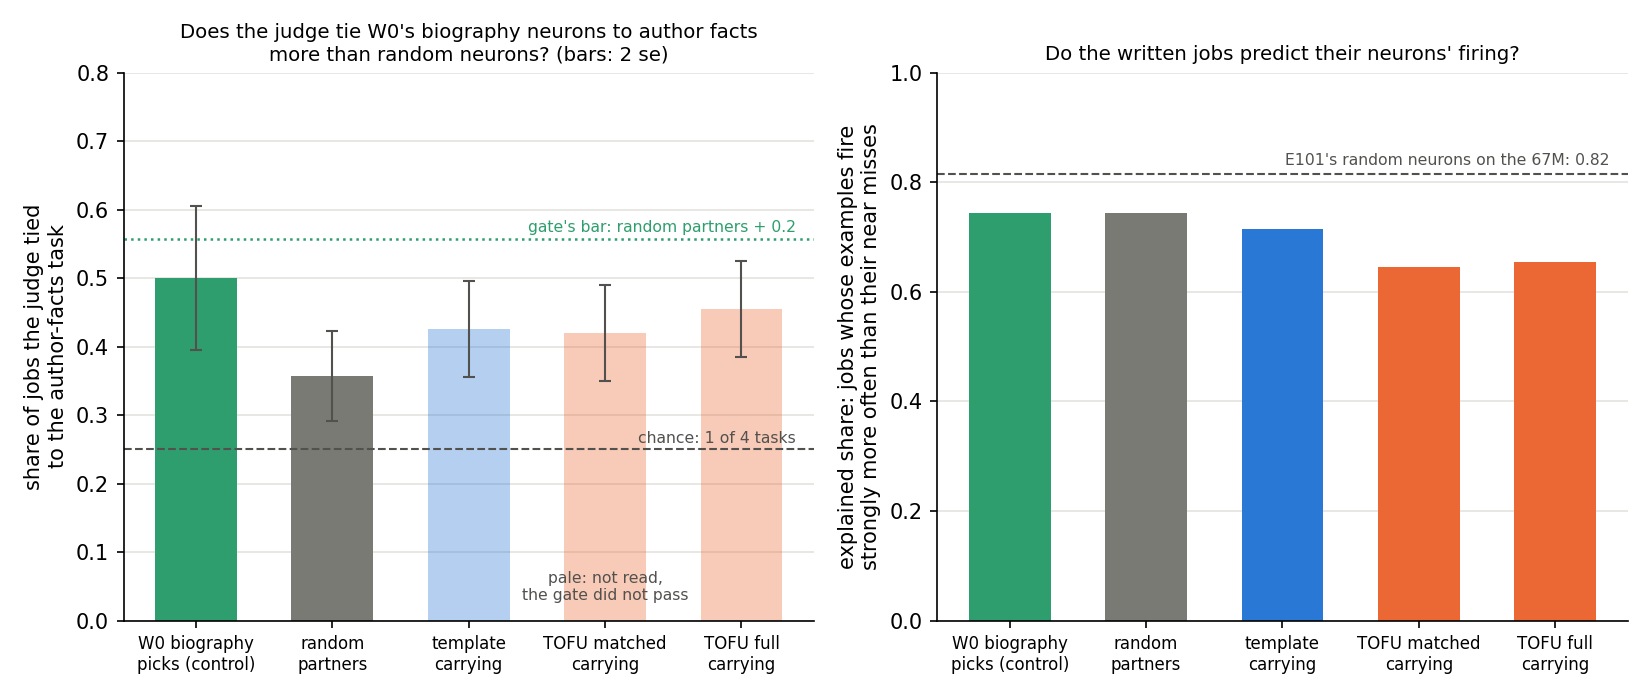

In [7]:
sb = json.loads((RES / "score_stageB.json").read_text())
gate = sb["CB1_power_gate"]["random"]
print(f"control tied to author facts: {gate['p1']:.3f} of {gate['n1']}; random partners {gate['p0']:.3f} of {gate['n0']}")
print(f"gap {gate['gap']:.3f}, two se {2 * gate['se']:.3f}, filed minimum gap 0.2: {sb['CB1_power_gate']['status']}")
display(Image(FIG / "stage_b.png", width=900))


**Reading it, left panel.** The judge has no power by the filed rule, so the gate reads no call. It tied the control
neurons to author facts in 45 of 90, a rate of 0.50, well above chance. But it tied the random partners to author facts
at 0.36 of 210, so the control leads by only 0.14. That clears two standard errors, 0.12, but not the filed minimum gap
of 0.2, the green dotted bar. Prose jobs drift to the one task not about maths, and the control did not rise far enough
above that drift.

So nothing else in stage B is read: the pale bars are printed only, and stage B stands as a judge without power on
Qwen. A no call is reported as what was read and opens no amendment, per the project's rules. The judge was not loose:
it marked only 11 of the 210 random partners a strong fit.

**Reading it, right panel.** The written jobs predict their neurons' firing for two thirds to three quarters of each
group, 0.65 to 0.74, below the 0.82 that random neurons read on the 67M. The two TOFU carrying groups sit 0.09 to 0.10
below the random partners, near two standard errors, in a comparison that was not filed.


## What we learned

The prompt overlap was meant as a cheap, decomposition-free test of reuse that VPD would have to beat. It does pick
out the neurons the system turn already uses, and the template fine-tune does lean on them. But a fine-tune on
unrelated facts at the same weight size leans on them nearly as much, so the overlap marks "a real small update" more
than "reuse of prompted behaviour". The engaged share carries no information at this grain.

Stage B asked whether naming the carrying neurons' jobs could separate the two where the overlap could not. Its judge
could not find biography neurons clearly where we know they are, so it cannot be trusted to read the fine-tunes'
neurons. For `GOALS.md`, neither neuron reading separates the labelled reuse case from the labelled new one on Qwen.
So the neuron route sets no bar VPD must beat on that question, and by its filed rule it stops here.

## How compelling is the evidence

- **Seeds.** Two per fine-tune; they agree closely on every stage A reading: 0.95 of shared carrying neurons for the
  template. Stage B pools both seeds per group.
- **Tasks.** One reuse fine-tune and one new-facts fine-tune, on their own rows. The prompt contrast exists only for
  the template task, so the TOFU states are read against a contrast built from another task's items.
- **Different rows.** The template and TOFU states are ranked on different rows. Against each one's own random change
  on its rows, the TOFU matched lead is larger than the template's: 2.5 points against 2.1. Either way the two are close.
- **Noise.** The filed band was 0.4 points, from the seed spread and twice the spread of 100 random draws. The gap
  between the template and the TOFU matched states, 0.5 points, is about one band.
- **Stage B's judge** ran once per batch, so its own noise is not measured. Three of its four tasks are about maths,
  which raises every group's author-facts rate. The plan's power sum expected the control near 0.7 against random near
  0.5; it read 0.5 against 0.36.
- **Blind to.** Relays, where a change upstream makes a later neuron re-fire; neurons the template moves that the system
  turn does not; the ranking is chosen on the same rows it is scored on; and jobs the writer cannot see in 20 windows.

## Surprises

- **The TOFU matched states overlap the prompt's neurons almost as much as the template fine-tune.** This was printed
  unscored and was expected to sit near the random change. It changes the reading of the one prediction that held.
- **The engaged share sat at 0.50 for every set.** The template prediction missed narrowly, by having no spread at all.
- **The random change's carrying set reproduces across row halves** at 0.61 and 0.86, so that reading cannot show a set
  belongs to its update.
- **Stage B's power gate did not pass**, where the lean was a pass. Random neurons drifted to author facts more, and
  the control less, than the plan assumed.
- Job 53016 died in its first minute on a file path, fixed in commit `31715646`; an environment fault, not a result.

## What next

1. **Read VPD's random references when they land.** If VPD's direct share separates the anchors beyond its random
   change, VPD does something both neuron readings cannot.
2. **A prompt contrast for TOFU**, such as a real author's biography with and without a system turn. If the TOFU states
   overlap their own contrast no more than the template's, the shared overlap here is a generic small-update effect.
   The job-naming route is closed on Qwen by its filed gate; reopening it would take a new plan, with a judge whose
   tasks are balanced between prose and maths.


## Scorecard

| id | claim in words | rule | read | verdict |
|---|---|---|---|---|
| C1 | the prompt contrast reproduces; the random change's set sits outside it | each gap at least 0.2 | halves 0.956 against draws 0.031; random change 0.035 | passes |
| P1 | template carrying sets lie in the prompt's contrast set | both seeds above the random change and draws, mean by more than the band | 0.056, 0.057 against 0.035, band 0.004 | holds |
| P2 | template carrying neurons already engaged at its answers | as P1, engaged share | 0.496, 0.500 against 0.509 | misses |
| P3 | TOFU matched states engaged no more than the random change | not above | 0.501, 0.499 against 0.507 | holds |
| R1 | TOFU full states, engaged share | reported | 0.501, 0.504 against 0.506 | not above |
| R2 | TOFU states' prompt overlap | printed, unscored | matched 0.051, 0.052; full 0.038, 0.040 | see the first claim |
| C2 | own windows beat other neurons' windows | win share at least 0.8 | 0.936 of 770 | passes |
| CB1 | judge ties the biography control to author facts | above random and chance, each by 0.2 and 2 se | 0.500 against random 0.357; gap 0.143, se 0.062 | no call: gate not passed |
| CB2 | judge's strong fits on random neurons | at most 0.5 | 0.052 of 210 | ok |
| PB1 | template carrying neurons pick layout more than TOFU matched | gap rule | 0.295 against 0.195 | not read |
| PB2 | TOFU full carrying neurons pick author facts above random | gap rule | 0.455 against 0.357 | not read |
| R | explained share per group | reported once C2 passes | 0.645 to 0.744; 67M random 0.82 | read |

## Departures from the literature

The neuron reading follows the essay at https://already-clean.goodfire.com/essay.md, "Explanations That Could Lose".

- **Ranking.** The essay ranks neurons by top activations on a corpus. Here neurons are ranked by their first-order
  effect on the fine-tune's gain, as in E98; only the engaged share and stage B's windows use corpus firing.
- **Model and corpus.** The essay reads Qwen3-32B; here Qwen3-1.7B, with FineWeb-Edu standing in for Qwen's
  pretraining text, which is not public.
- **Writer and maximiser.** The essay's jobs come from an investigating agent with tools; here Sonnet agents with no
  tools, one call per batch of 30, because 78 calls fit the budget and 770 investigations did not.
- **Win rule.** The essay does not state its rule; ours counts strong examples against strong near misses, with the
  essay's 30% bar for strong.
- **Judge.** Not in the essay: a forced-choice Sonnet judge ties each job to one of four project tasks.
- **E94's Gaussian change** is scaled there to match a masked loss gap; here to match anchor 1's clean KL on 16 maths
  rows, so no decomposition is loaded.
- **One set size, 1,024,** for every state, where E101 used each state's own half-gain size; chance is then the same.
- **Firing is read signed** in stage A; the essay and stage B read only the positive side.

## Not run

- The two stage B predictions on the fine-tunes' neurons: not read, by the power gate's filed rule.
- Stage B on the random change's carrying sets; a second judge call per batch; a judge with balanced tasks.
- Steering or ablating any carrying neuron.
- A prompt contrast for the TOFU task.
- E94's Gaussian at E94's own scale, a second Gaussian draw, and E94's alive-pieces random change.
- TOFU's states just past the learning line, and the GRPO states.
- VPD's random references for the direct share, and VPD's rows for the full TOFU states: not in E94's `table.json`.

## Provenance

Results `experiments/qwen_carrying/results/{control,gauss,w0,score}.json`, `states/*.json`, `run.log`; figures from
`experiments/qwen_carrying/plot.py`. Jobs 53025 (W0 stage, random change, template states, 723 s) and 53029 (four TOFU
states, 411 s), one L40 on the MATS `debug` QoS, $0. Job 53016 stopped on a path bug, fixed in `31715646`. Stage B:
agent outputs `results/stage_b/{writer,maximiser,judge}/`, 78 Sonnet calls; scoring job 53068, one L40 on `debug`, 106 s,
$0; score `results/score_stageB.json`.
